# Flower Classification Project

Your task is to **classify photos of flowers as roses, sunflowers or tulips**, with only 100 photos per kind of flower to learn from, using **transfer learning**.

# The Business Problem

A garden centre runs a website where customers upload a photo of a flower from their garden and receive a care guide for it: when to water, when to cut it back, which pests to watch for. At the moment, a member of staff looks at every photo and chooses the right guide by hand. The garden centre starts with its three most requested guides, **roses, sunflowers and tulips**, and wants a model that chooses the guide automatically from the photo.

Your model answers this question: given a photo, which of the three flowers does it show? A wrong answer sends a customer the wrong care guide, so at the end you look at **which photos the model gets wrong**, so that the garden centre knows when to trust it and when a member of staff should check the answer.

The model can only answer with one of the three flowers. A photo of a daisy would still receive one of the three labels, so the website has to make clear which flowers the service covers.

# Data Description

The data ships with this repository in the folder `data/`: **390 colour photos**, one JPEG file per photo, sorted into one folder per kind of flower. The name of the folder is the label of the photo.

| Folder | Photos | Description |
| :-- | :-- | :-- |
| `data/train/rose` | 100 | roses, for training |
| `data/train/sunflower` | 100 | sunflowers, for training |
| `data/train/tulip` | 100 | tulips, for training |
| `data/validation/rose` | 20 | roses, for choosing the model |
| `data/validation/sunflower` | 20 | sunflowers, for choosing the model |
| `data/validation/tulip` | 20 | tulips, for choosing the model |
| `data/test/rose` | 10 | roses, **the test set** |
| `data/test/sunflower` | 10 | sunflowers, **the test set** |
| `data/test/tulip` | 10 | tulips, **the test set** |

The photos have different sizes, from 159 to 640 pixels wide, and show the flowers in very different ways: a single flower close up, a whole field, a bunch in a vase, sometimes with people or buildings in the picture.

The photos are part of the [TensorFlow flower photos](https://www.tensorflow.org/datasets/catalog/tf_flowers) collection and were taken from Flickr. Every photo is licensed under [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/); its photographer is listed in `data/LICENSE.txt`.

## Task

1. **Get the data.** Display a few photos of every class from `data/train`.
2. **Load the training and the validation images.** Load `data/train` and `data/validation` with `keras.utils.image_dataset_from_directory`, with one `image_size` that you use for every model, for example `(160, 160)`. Shuffle the training images with a fixed `seed`; keep the validation images in their order with `shuffle=False`. Do not load `data/test` until step 6.
3. **Explore the training set.** Display a grid of training photos with their labels. What makes the three flowers look different: colour, shape, the background?
4. **Repurpose a pretrained network.** Use `MobileNetV2` from `keras.applications` as the pretrained network and repurpose it to classify the three flowers. Plot its learning curves: does it overfit?

> [!IMPORTANT]
> **Every image has to be prepared in exactly the same way**: the same `image_size`, the same `preprocess_input` of the base, and the same frozen base, for the training, the validation and later the test images.

5. **If needed, improve the model with data augmentation**, and compare the validation accuracy with step 4. Choose your best model by its validation accuracy. **Save every model to a file** with `model.save`, for example `models/dense_head.keras`, so that you can load all of them in step 6 with `keras.models.load_model`, even after restarting the notebook.
6. **Evaluate all models on the test set at the very end.** Load your saved models, and load `data/test` with the same `image_size` and with `shuffle=False`. Then:
    1. Collect the **validation and test accuracy of every model** in **one table**. Is the validation accuracy of your chosen model a fair estimate of its test accuracy? The test set has only 30 photos, so **one photo changes the test accuracy by 3.3 percentage points**.
    2. **Plot the confusion matrix** of your best model on the test set. Which flowers does it confuse?
    3. **Display every misclassified test photo**, with its true and predicted label. What do these photos have in common?
7. **Try your model in an app.** The repository contains a small [Streamlit](https://docs.streamlit.io/) app, `app.py`, that loads a model from `models/` and classifies a photo that you upload. Start it in a terminal in the repository folder with `uv run streamlit run app.py`, choose your best model, and upload a few flower photos of your own. Does the model get them right? The app works with models that take the raw photos and include their preprocessing, such as `preprocess_input`, as layers.

# Our Approach

**The question.** Can a model choose the right care guide, rose, sunflower or tulip, from a customer's photo, when we have only 100 training photos per flower? And when can the garden centre trust its answer?

**The idea: transfer learning.** 300 photos are far too few to train a convolutional network from scratch: its filters would have to learn edges, textures and shapes from these few photos alone, and it would memorise them. Instead we reuse **MobileNetV2**, a network that has already learnt to see from about 1.4 million ImageNet photos. We keep the part that turns a photo into features and only train a small new classifier for our three flowers.

**The plan.**

| Step | What we do | Why |
|---|---|---|
| 1 | Count and look at the photos | Know the data, check that the classes are balanced |
| 2 | Load training and validation images | Prepare the photos the same way for every model |
| 3 | Explore one batch | Find out what separates the flowers and where the model may struggle |
| 4 | Frozen MobileNetV2 + a small dense head, then a CNN from scratch for comparison | The simplest transfer learning model, our first real result, and proof of how much the pretraining helps |
| 5 | Add data augmentation, compare, choose | Try to reduce the overfitting of step 4, then pick the best model on the validation set |
| 6 | Test set, confusion matrix, wrong photos | One honest final score, and when the model can be trusted |
| 7 | Try the model in the app | Use it the way a customer would |

The **test set stays locked** until step 6, so that our choices in steps 4 and 5 cannot be tuned to it.

# Methods and Decisions at a Glance

Every choice in this project, with the reason for it and what we considered instead. The details are in the steps.

**Data and evaluation**

| Decision | Our choice | Why | Considered instead |
|---|---|---|---|
| Split | Use the given folders: 300 training, 60 validation, 30 test photos | Separate sets for learning, choosing and the final check | Splitting ourselves: not needed, the folders are already balanced |
| Test set | Locked until step 6, used once | Choices made on the test set would make its score too optimistic | |
| Metric | Accuracy, plus confusion matrix, wrong photos and confidence | The three classes are balanced (100 / 100 / 100), so accuracy is fair; the rest shows *where* and *why* it goes wrong | |
| Baselines | Chance (0.333) and a CNN trained from scratch | Show what "good" means and how much transfer learning helps | |
| Model choice | On validation accuracy; if two models are within one or two photos, the simpler one | With 60 photos, one photo is 0.017, so small differences are chance | Choosing on the test set: not allowed |

**Preparing the photos**

| Decision | Our choice | Why | Considered instead |
|---|---|---|---|
| Image size | 160 x 160 pixels | MobileNetV2 accepts it and it halves the computing time compared with 224 x 224 | 224 x 224, the original size: slower on our CPU |
| Aspect ratio | Squeeze every photo to a square (the default) | All three flowers have the same median shape (1.33), so no flower gets a hint | `crop_to_aspect_ratio=True`: could cut off a flower at the edge |
| Batch size | 32 | The Keras default; 300 photos give about 10 updates per epoch | |
| Shuffling | Training shuffled with seed 42; validation and test not shuffled | Every batch mixes the flowers; a fixed order keeps photos and labels matched | |
| Random seed | 42 everywhere | Reproducible results | |
| Pixel scaling | 0..255 to -1..1, as a `Rescaling` layer inside the saved model | What MobileNetV2 was trained with; inside the model, the app prepares photos the same way | `preprocess_input` outside the model: the app would skip it |

**The model**

| Decision | Our choice | Why | Considered instead |
|---|---|---|---|
| Approach | Transfer learning | 300 photos are too few to train from scratch: the CNN from scratch reaches only 0.633 | CNN from scratch, as baseline |
| Pretrained network | MobileNetV2, ImageNet weights | Small (9 MB) and fast on a CPU, built for apps; the network used in class | EfficientNetB0 (from class), not tried |
| Base | `include_top=False`, `pooling="avg"`, frozen | Remove the 1,000-class classifier, get 1,280 features, protect the 2.26 million pretrained weights | Fine-tuning the top layers, not tried |
| Training the head | Features extracted once, then the head trained on the table | The frozen base always gives the same features, so this takes seconds | |
| Head | `Dropout(0.2)` + `Dense(3, softmax)`, 3,843 weights | Dropout against overfitting; softmax gives three probabilities | A hidden layer: not needed for 0.867 |
| Loss and optimiser | Sparse categorical cross-entropy, Adam with learning rate 0.001 | Integer labels 0, 1, 2; the standard settings from class | |
| Epochs | Head 30, augmented model 10, CNN 20 | Head: seconds per epoch. Augmented model: the base runs every epoch, so it is slower | |
| Early stopping | Tested, not used | Lower validation loss, but 2 validation photos fewer | |
| Augmentation | Horizontal flip, rotation up to 36 degrees, zoom up to 10 % | Changes that keep the label true | Vertical flip and colour changes: create photos that do not occur |
| Final model | Features + dense head | Highest validation accuracy (0.867), tied with augmentation, and simpler | Frozen base + augmentation (0.850) |
| Staff check | Every answer below 70 % | On the test set it catches 2 of 3 mistakes and sends no correct answer to staff | Must be confirmed on more photos: it was chosen on the 30 test photos |

In [1]:
# Import the libraries you need for this project
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from keras.applications import mobilenet_v2

from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

#### Setting up the Seed, Image Size and Plot Style

Settings used by every step: a fixed random seed, so that every run gives the same results and our numbers can be reproduced; one image size for all photos, because a network needs every input in the same shape; the path to the data; and one plot style.

In [2]:
# Make every random step (shuffling, starting weights, dropout) the same in every run, so the results are reproducible
keras.utils.set_random_seed(42)

IMAGE_SIZE = (160, 160)  # MobileNetV2 also accepts 160 x 160, which halves the computing time
DATA = Path("data")  # the folder with train/, validation/ and test/, one subfolder per flower

# One plot style for the whole notebook: no top and right frame lines, a light grid
plt.rcParams.update(
    {"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3}
)

## 1. Getting the Data

**Why this step.** Before building a model we need to know what we are working with. First we count the photos of every flower in each split: if one flower had many more photos, a model could score well just by guessing that flower, and accuracy would be misleading. Then we look at the first five training photos of every flower, to see how varied they are.

In [3]:
CLASSES = ["rose", "sunflower", "tulip"]  # the folder names, which are also the labels

# Count the .jpg files in data/<split>/<flower>/ for every split and every flower,
# and show the counts as a table: one row per flower, one column per split
pd.DataFrame(
    {split: {name: len(list((DATA / split / name).glob("*.jpg"))) for name in CLASSES}
     for split in ["train", "validation", "test"]}
).style.set_caption("Number of photos per flower in each split")

,train,validation,test
rose,100,20,10
sunflower,100,20,10
tulip,100,20,10


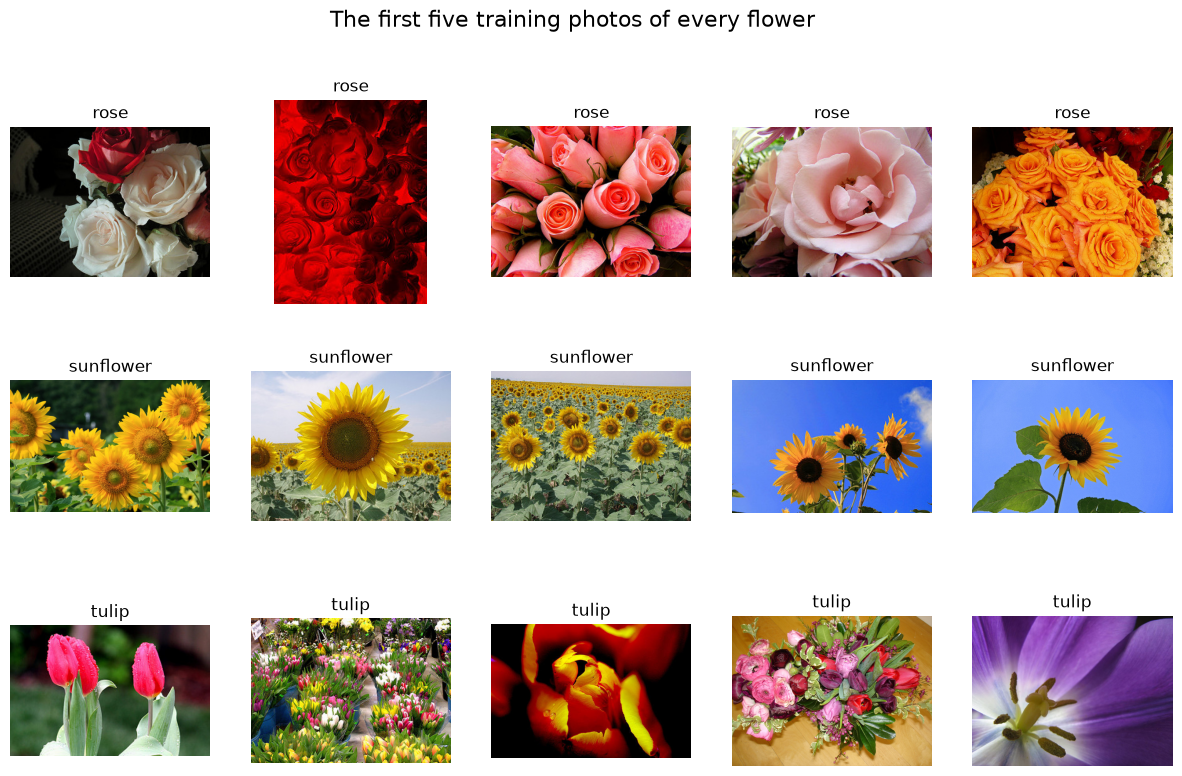

In [4]:
# A grid of 3 rows (one per flower) and 5 columns (five photos per flower)
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for row, flower in enumerate(CLASSES):  # row 0 = rose, 1 = sunflower, 2 = tulip
    paths = sorted((DATA / "train" / flower).glob("*.jpg"))[:5]  # the first five photo files of this flower
    for col, path in enumerate(paths):
        axes[row, col].imshow(keras.utils.load_img(path))  # open the photo file and draw it in its box
        axes[row, col].set_title(flower)  # the label above the photo
        axes[row, col].axis("off")  # hide the axes, they mean nothing for a photo
fig.suptitle("The first five training photos of every flower", fontsize=16)
plt.show()

**Result.** Each flower has 100 training, 20 validation and 10 test photos, so the classes are balanced and accuracy is a fair metric: guessing would give 33 %. The photos differ a lot: single flowers close up, whole fields, bunches in vases. Sunflowers are easy to recognise by their yellow petals and dark centre. Roses and tulips share the same colours (red, pink, white), so we expect the model to confuse these two most.

### How Much Are the Photos Stretched?

**Why.** `image_dataset_from_directory` resizes every photo to 160 x 160 pixels **without keeping its shape**, so every photo that is not square is squeezed. This plot shows how many photos are affected and how strongly, and the table checks whether one flower is affected more than the others, which would give the model a hint that has nothing to do with the flower.

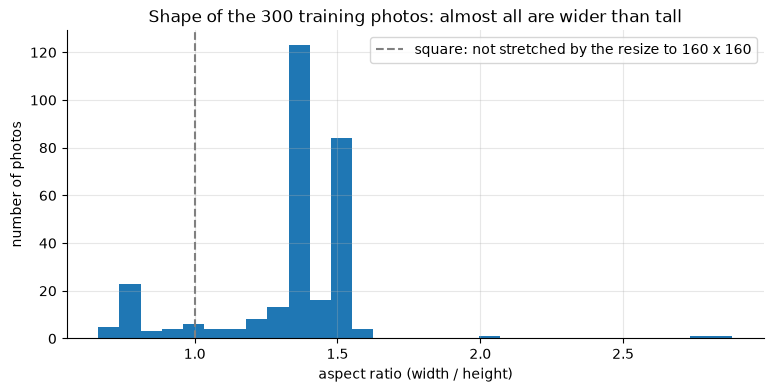

Square photos (aspect ratio 0.95 to 1.05): 7 of 300


,width,height,aspect ratio
flower,,,
rose,320.000000,245.000000,1.330000
sunflower,320.000000,256.000000,1.330000
tulip,320.000000,240.000000,1.340000


In [5]:
# Width and height of every training photo, read from the file without loading the pixels
sizes = pd.DataFrame(
    [(path.parent.name, *keras.utils.load_img(path).size) for path in sorted((DATA / "train").glob("*/*.jpg"))],
    columns=["flower", "width", "height"],
)
sizes["aspect ratio"] = sizes["width"] / sizes["height"]  # 1 = square, 1.33 = a usual 4:3 photo, below 1 = portrait

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(sizes["aspect ratio"], bins=30)
ax.axvline(1, color="grey", linestyle="--", label="square: not stretched by the resize to 160 x 160")
ax.set_xlabel("aspect ratio (width / height)")
ax.set_ylabel("number of photos")
ax.set_title("Shape of the 300 training photos: almost all are wider than tall")
ax.legend()
plt.show()

print(f"Square photos (aspect ratio 0.95 to 1.05): {sizes['aspect ratio'].between(0.95, 1.05).sum()} of {len(sizes)}")
sizes.groupby("flower")[["width", "height", "aspect ratio"]].median().round(2).style.set_caption(
    "Median width, height and aspect ratio per flower"
)

**Result.** Only 7 of the 300 training photos are square. Almost all are wider than tall, mostly in the usual photo formats 4:3 (aspect ratio 1.33) and 3:2 (1.5); a few are portrait (about 0.75), and two panoramas reach 2 and 2.9. So almost every photo is squeezed: a 4:3 photo becomes a quarter narrower. The median aspect ratio is 1.33 for **all three flowers**, so the squeezing affects every flower in the same way and gives the model no hint about the class. Because every photo, in training, validation, test and the app, is prepared the same way, the model learns and is tested on the same squeezed shapes. An alternative would be `crop_to_aspect_ratio=True`, which cuts the photo to a square instead, but could cut off a flower at the edge.

**→ Next:** load the photos in a form the network can use.

## 2. Loading the Training and Validation Images

**Why this step.** A network needs every photo as numbers of the same shape, with its label. We use two separate sets with two different jobs: the **training** photos are what the model learns from, the **validation** photos are what we use to compare models and choose one. The model never learns from the validation photos, so their score shows how well it handles new photos.

`image_dataset_from_directory` reads the photos from the folders: the name of each subfolder becomes the label. Every photo is resized to `IMAGE_SIZE` and grouped into batches of 32. The training images are shuffled with a fixed seed, so that every batch mixes the three flowers; the validation images keep their order (`shuffle=False`). The test set stays locked until step 6.

In [6]:
IMAGE_SIZE = (160, 160)  # the same size for every photo and every model
BATCH_SIZE = 32  # the number of photos the model processes at once
SEED = 42  # fixes the shuffle order, so every run uses the same order

# Training photos: shuffled, so that each batch mixes roses, sunflowers and tulips
train_ds = keras.utils.image_dataset_from_directory(
    DATA / "train", image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    shuffle=True, seed=SEED,
)
# Validation photos: not shuffled, their order does not matter for scoring and stays fixed
val_ds = keras.utils.image_dataset_from_directory(
    DATA / "validation", image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    shuffle=False,
)
class_names = train_ds.class_names  # the folder names in alphabetical order: label 0, 1, 2
print(class_names)

Found 300 files belonging to 3 classes.


Found 60 files belonging to 3 classes.


['rose', 'sunflower', 'tulip']


**Result.** 300 training and 60 validation photos, in three classes. The labels are numbers in alphabetical order of the folders: 0 = rose, 1 = sunflower, 2 = tulip.

**→ Next:** look at the photos the way the model receives them.

## 3. Exploring the Training Set

**Why this step.** Before training, we want to know what makes the three flowers different, and where a model could go wrong, so that we can check these expectations against the real mistakes in step 6.

We show one shuffled batch of training photos with their labels, as the model receives them: resized to 160 x 160. Then we check the pixel values and how the three flowers are mixed in the batch.

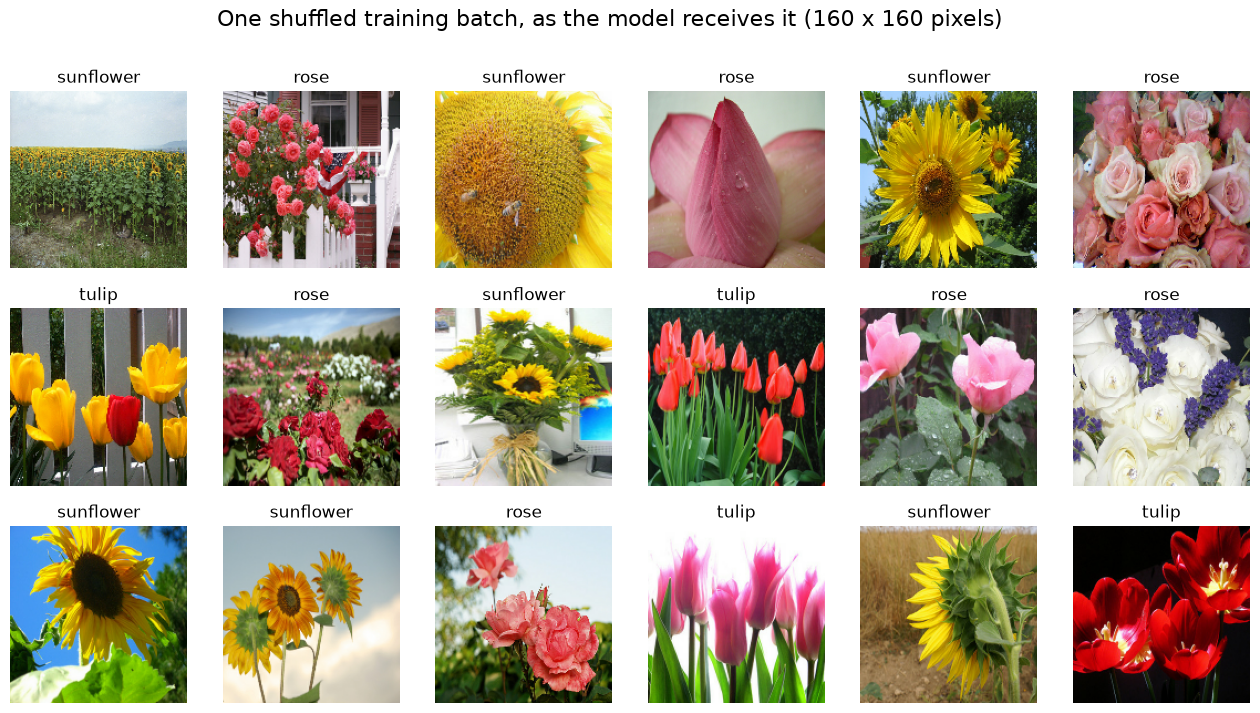

In [7]:
images, labels = next(iter(train_ds))  # the first batch of 32 images and their labels (0, 1 or 2)

# Show the first 18 photos of the batch in a grid of 3 rows and 6 columns
fig, axes = plt.subplots(3, 6, figsize=(16, 8))
for ax, image, label in zip(axes.flat, images, labels):
    ax.imshow(image.numpy().astype("uint8"))  # convert the pixel values to whole numbers from 0 to 255 for drawing
    ax.set_title(class_names[label])  # turn the label number into the flower name
    ax.axis("off")
fig.suptitle("One shuffled training batch, as the model receives it (160 x 160 pixels)", fontsize=16)
plt.show()

In [8]:
print("Pixel range:", images.numpy().min(), "to", images.numpy().max())  # still 0 to 255: the scaling to -1 to 1 comes later, inside the model
print("\nFlowers in this batch of 32 photos:")
print(pd.Series(labels.numpy()).map(dict(enumerate(class_names))).value_counts())  # how the flowers are mixed in this shuffled batch

Pixel range: 0.0 to 255.0

Flowers in this batch of 32 photos:
rose         12
sunflower    11
tulip         9
Name: count, dtype: int64


### Which Colours Does Each Flower Have?

**Why.** In the photos, colour looks like the most obvious difference between the flowers. This plot checks how much it really separates them: for every training photo it counts the **hue** of the clearly coloured pixels, their position on the colour wheel (0 = red, 60 = yellow, 120 = green, 240 = blue, 300 = pink and purple, back to red at 360). Grey, white and black pixels are left out.

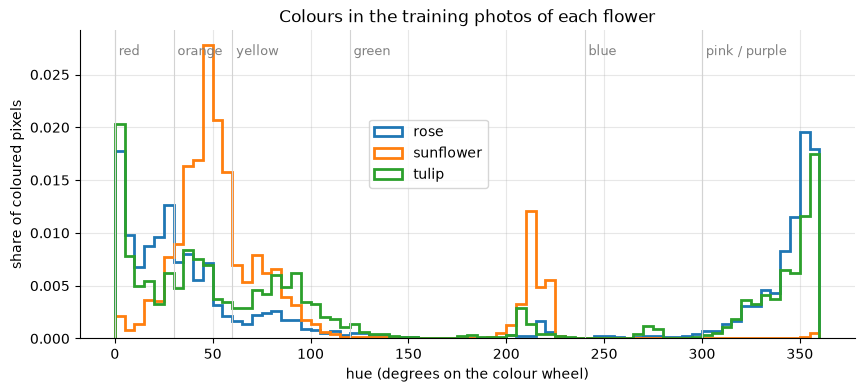

In [9]:
# Which colours does each flower have? For every training photo (shrunk to 64 x 64 pixels for speed),
# keep only the clearly coloured pixels and count their hue, the colour on the colour wheel (0 = red, 60 = yellow, ...)
hue_degrees = {}
for flower in class_names:
    hues = []
    for path in sorted((DATA / "train" / flower).glob("*.jpg")):
        hsv = np.asarray(keras.utils.load_img(path, target_size=(64, 64)).convert("HSV"), dtype=float) / 255
        colourful = (hsv[..., 1] > 0.4) & (hsv[..., 2] > 0.3)  # saturated and not too dark: skips grey, white and black
        hues.append(hsv[..., 0][colourful] * 360)  # hue from 0..1 to degrees
    hue_degrees[flower] = np.concatenate(hues)

fig, ax = plt.subplots(figsize=(10, 4))
for flower, hues in hue_degrees.items():
    ax.hist(hues, bins=72, range=(0, 360), density=True, histtype="step", linewidth=2, label=flower)
for degrees, colour_name in [(0, "red"), (30, "orange"), (60, "yellow"), (120, "green"), (240, "blue"), (300, "pink / purple")]:
    ax.axvline(degrees, color="lightgrey", linewidth=0.8)
    ax.text(degrees + 2, ax.get_ylim()[1] * 0.92, colour_name, fontsize=9, color="grey")
ax.set_xlabel("hue (degrees on the colour wheel)")
ax.set_ylabel("share of coloured pixels")
ax.set_title("Colours in the training photos of each flower")
ax.legend(loc="center", bbox_to_anchor=(0.45, 0.6))
plt.show()

**Result.** **Sunflowers** stand apart: most of their coloured pixels are orange-yellow (about 40 to 55 degrees), and they have a second peak in **blue (about 210 degrees): the sky**. Many sunflower photos are taken outside against a blue sky, so the model could learn "blue sky means sunflower". **Roses and tulips have almost the same colours**: red (around 0 and 350 degrees), pink and some orange. Colour alone can therefore separate sunflowers, but not roses from tulips; for these two the model needs shape.

**Result.** The shuffled batch mixes all three flowers, so training never sees 100 roses in a row. The pixel values are still 0 to 255; they are scaled to -1 to 1 later, inside the model.

- **Colour helps only for sunflowers** (yellow with a dark centre), as the colour plot above confirms. Roses and tulips share red, pink, white and orange, and tulips can also be yellow, so the model has to learn **shape**: the dense, layered petals of a rose, the smooth cup of a tulip on a long straight stem, the flat disc of a sunflower.
- **Scale and viewpoint vary a lot**: single flowers close up, whole fields, bouquets in vases, a closed bud, a sunflower seen from behind.
- **The backgrounds differ**: sky, fields, fences, houses, a desk. Sunflowers often appear with blue sky or fields (the blue peak in the colour plot), so the model might learn **"sky means sunflower"** as a shortcut instead of the flower itself. We check this with the misclassified photos in step 6.
- **Expected confusion:** roses and tulips, especially on bouquets, photos taken from far away and closed buds, where the petal shape is hard to see.
- **Data quality:** one photo labelled rose (the pink bud in the top row) looks more like a lotus, so the data contains a few doubtful labels. All photos are squeezed to 160 x 160 without keeping their aspect ratio (see step 1); every flower is affected in the same way, so the model learns with this.

**Looking ahead to step 5.** A horizontal flip is a sensible augmentation, because a mirrored flower is still the same flower, and so are small rotations and zooms, because photos are taken at slightly different angles and distances. A vertical flip is not: most photos have a natural up and down, with the sky above and the stems and ground below, so a flipped photo would show a scene that never occurs. It would only suit close-ups taken from above.

**→ Next:** the first model.

## 4. Repurposing MobileNetV2

**Why this step.** This is the core of the project: the simplest way to use a pretrained network for our own task, and the result every later model is compared with.

MobileNetV2 is a network pretrained on ImageNet, about 1.4 million photos in 1,000 classes. Its convolutional layers have learnt to detect edges, textures and shapes, which are useful for any photo, including flowers; its last layer, which picks one of the 1,000 ImageNet classes, is of no use to us. So we keep the **base** and replace the last layer with a small **head** for our three flowers:

- Without its ImageNet classifier (`include_top=False`) and with `pooling="avg"`, the base turns every photo into 1,280 features.
- The base is **frozen** (`base.trainable = False`): its 2.26 million weights stay as they are. This protects what it learnt, and with only 300 photos it keeps the model from memorising them.
- Because the frozen base always gives the same features for the same photo, the features are extracted **once**, and the small head is trained on them in seconds.

### Load and Freeze the Base, Extract the Features

The base is loaded without its ImageNet classifier and frozen. `extract_features` runs it **once** over every photo: it scales the pixels as MobileNetV2 expects, turns each photo into 1,280 numbers, and keeps the labels of the same batch. The result is an ordinary table: one row per photo, 1,280 columns.

In [10]:
# Load MobileNetV2 with the weights it learned on ImageNet:
# include_top=False removes its classifier for the 1,000 ImageNet classes,
# pooling="avg" averages its last feature maps into one vector of 1,280 numbers per photo
base = mobilenet_v2.MobileNetV2(include_top=False, weights="imagenet", input_shape=IMAGE_SIZE + (3,), pooling="avg")
base.trainable = False  # freeze the base: training will not change its weights


def extract_features(dataset):
    """Run the frozen base over every batch of a dataset; return the feature vectors and the labels."""
    all_features = []
    all_labels = []
    for images, labels in dataset:  # one batch of up to 32 images at a time
        images = mobilenet_v2.preprocess_input(images)  # scale the pixels from 0 to 255 to -1 to 1
        features = base.predict(images, verbose=0)  # one row of 1,280 numbers per image
        all_features.append(features)
        all_labels.append(labels.numpy())  # the labels of the same batch, so they stay in the order of the images
    return np.concatenate(all_features), np.concatenate(all_labels)  # stack the batches into one table


# The training set is loaded again without shuffling: a shuffled dataset changes its order every time
# you loop over it, so the labels could end up in a different order from the features
X_train, y_train = extract_features(keras.utils.image_dataset_from_directory(
    DATA / "train", image_size=IMAGE_SIZE, shuffle=False
))
X_valid, y_valid = extract_features(val_ds)
print("Training features:", X_train.shape, " validation features:", X_valid.shape)  # (photos, features)

Found 300 files belonging to 3 classes.


Training features: (300, 1280)  validation features: (60, 1280)


### Train the Dense Head

The head is the new classifier on top of the frozen base. It has a `Dropout` layer, which hides 20 % of the features at random during training so that the head cannot rely on a few of them, and a `Dense` layer with one output per flower; `softmax` turns the three outputs into probabilities that add up to 1. Only the head is trained: 1,280 x 3 weights + 3 biases = 3,843 numbers. After every epoch, Keras also measures the loss and accuracy on the validation features, which gives the learning curves.

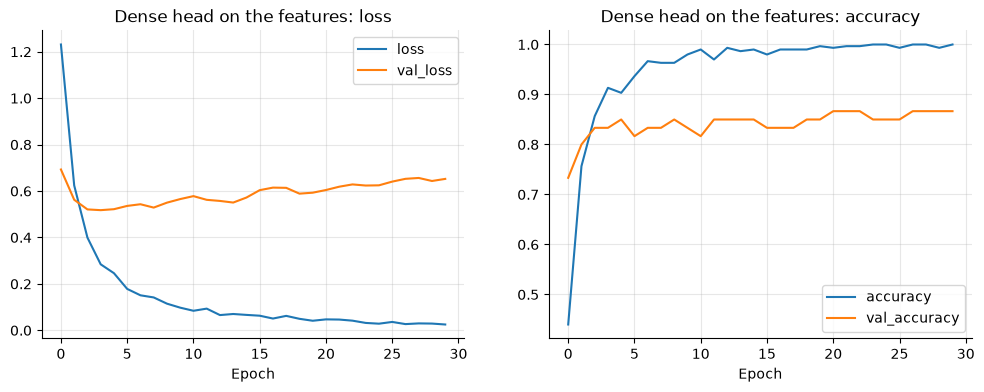

Trainable parameters of the head: 3,843
Validation accuracy: 0.867


In [11]:
def plot_curves(logs, title):
    """Plot the training and validation loss and accuracy of one run."""
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))  # two plots side by side
    logs[["loss", "val_loss"]].plot(ax=ax_loss, xlabel="Epoch", title=f"{title}: loss")
    logs[["accuracy", "val_accuracy"]].plot(ax=ax_acc, xlabel="Epoch", title=f"{title}: accuracy")
    plt.show()


keras.utils.clear_session()  # start from a clean Keras state
keras.utils.set_random_seed(42)  # the same random starting weights in every run

head = keras.Sequential(
    [
        keras.Input(shape=(X_train.shape[1],)),  # input: the 1,280 features of one photo
        keras.layers.Dropout(0.2),  # during training, hide 20 % of the features at random
        keras.layers.Dense(units=len(class_names), activation="softmax"),  # one probability per flower
    ],
    name="dense_head",  # a clear name in summary() and inside the saved model
)
head.compile(
    loss="sparse_categorical_crossentropy",  # the loss for integer labels 0, 1, 2
    optimizer=keras.optimizers.Adam(1e-3),  # Adam with learning rate 0.001
    metrics=["accuracy"],
)
# Train for 30 epochs on the training features and measure the validation features after every epoch
head_history = head.fit(X_train, y_train, validation_data=(X_valid, y_valid), epochs=30, verbose=0)
plot_curves(pd.DataFrame(head_history.history), "Dense head on the features")
print(f"Trainable parameters of the head: {head.count_params():,}")

results = {}  # the validation accuracy of every model, to compare them in step 5
results["Features + dense head"] = head.evaluate(X_valid, y_valid, verbose=0)[1]  # [loss, accuracy] -> accuracy
print(f"Validation accuracy: {results['Features + dense head']:.3f}")

**Result.** The dense head reaches a validation accuracy of 0.867, 52 of the 60 photos, after a few seconds of training, with only 3,843 trainable weights (1,280 features x 3 flowers + 3 biases). The frozen MobileNetV2 features already describe the flowers well enough for a single dense layer to separate them; chance would be 0.333.

**Does it overfit?** Yes, a little. The training accuracy reaches 1.0 and the training loss falls close to 0, while the validation accuracy levels off between 0.82 and 0.87 after about 3 epochs. The validation loss is lowest at about epoch 4 and then rises slowly: the head memorises the 300 training photos and becomes over-confident, but it does not get more validation photos wrong. In step 5 we try data augmentation to reduce this overfitting.

### Would Early Stopping Help?

**Why.** The learning curves show that the validation loss is lowest after about 4 epochs and then rises while the head keeps training for 30. **Early stopping**, from the regularisation notebook of day 2, stops training when the validation loss has not improved for a few epochs (`patience`) and goes back to the weights of the best epoch (`restore_best_weights=True`). We train the same head again with early stopping and compare it with the 30-epoch head, without replacing it yet.

In [12]:
# The 30-epoch head from above, measured before the Keras state is cleared
loss_30, accuracy_30 = head.evaluate(X_valid, y_valid, verbose=0)

keras.utils.clear_session()
keras.utils.set_random_seed(42)  # the same random starting weights as the 30-epoch head

# The same head as above, trained again with early stopping
head_early = keras.Sequential(
    [
        keras.Input(shape=(X_train.shape[1],)),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(units=len(class_names), activation="softmax"),
    ],
    name="dense_head_early_stopping",
)
head_early.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.Adam(1e-3), metrics=["accuracy"])
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",  # watch the validation loss
    patience=5,  # stop after 5 epochs without improvement
    restore_best_weights=True,  # go back to the weights of the best epoch
)
early_history = head_early.fit(
    X_train, y_train, validation_data=(X_valid, y_valid), epochs=30, callbacks=[early_stopping], verbose=0
)
best_epoch = int(np.argmin(early_history.history["val_loss"])) + 1  # epochs are counted from 1
loss_early, accuracy_early = head_early.evaluate(X_valid, y_valid, verbose=0)
print(f"Early stopping stopped after {len(early_history.history['loss'])} epochs and kept the weights of epoch {best_epoch}")

pd.DataFrame(
    {
        "validation loss": [loss_30, loss_early],
        "validation accuracy": [accuracy_30, accuracy_early],
        "correct (of 60)": [round(accuracy_30 * 60), round(accuracy_early * 60)],
    },
    index=["30 epochs (chosen)", f"early stopping (weights of epoch {best_epoch})"],
).style.format(precision=3).set_caption("Dense head: 30 epochs against early stopping")

Early stopping stopped after 9 epochs and kept the weights of epoch 4


,validation loss,validation accuracy,correct (of 60)
30 epochs (chosen),0.652,0.867,52
early stopping (weights of epoch 4),0.518,0.833,50


**Result.** Early stopping stops after 9 epochs and goes back to the weights of epoch 4. Its validation loss is clearly lower, 0.518 instead of 0.652: its probabilities are less over-confident. But its validation accuracy is lower, 0.833 instead of 0.867: **2 photos fewer** of the 60.

**Decision: We keep the head trained for 30 epochs.** At the start we chose accuracy as the metric, because the garden centre needs the right care guide, and on accuracy the 30-epoch head is ahead. The difference is only 2 photos, though, and the early-stopped head gives more honest probabilities, which matters for the staff-check rule in step 6. With more validation photos, we would compare the two again.

### Save the Model for the App

**Why.** The head expects 1,280 features, but the app and the test set give the model raw photos with pixel values from 0 to 255. To use the head there, we build one model that does every step in a row and save it to a file, so that we can load it again in step 6, even after a restart.

The saved model puts the same preparation in front of the head: a `Rescaling` layer, which scales the pixels exactly like `mobilenet_v2.preprocess_input`, and the frozen base. If this model reaches the same validation accuracy on the photos as the head on the features, every image is prepared in exactly the same way.

In [13]:
# One model from raw photo to probabilities, built from the parts of step 4 (nothing new is trained)
dense_head_model = keras.Sequential(
    [
        keras.Input(shape=IMAGE_SIZE + (3,)),  # input: one photo of 160 x 160 pixels with 3 colour channels
        keras.layers.Rescaling(scale=1 / 127.5, offset=-1),  # pixels 0..255 -> -1..1, the same as mobilenet_v2.preprocess_input
        base,  # the frozen MobileNetV2 base: photo -> 1,280 features
        head,  # the trained head: 1,280 features -> 3 probabilities
    ],
    name="features_dense_head",  # a clear name in summary() and inside the saved model
)
dense_head_model.summary()  # the layers of the complete model, and how many weights are trained or frozen
dense_head_model.compile(loss="sparse_categorical_crossentropy", metrics=["accuracy"])  # needed for evaluate, no training

# Check: on the validation photos it must give the same accuracy as the head on the features (0.867)
print(f"Validation accuracy on the photos: {dense_head_model.evaluate(val_ds, verbose=0)[1]:.3f}")

Path("models").mkdir(exist_ok=True)  # create the folder models/ if it does not exist yet
dense_head_model.save("models/dense_head.keras")  # one file with the scaling, the base and the head


Model: "features_dense_head"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_head (Sequential)         │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Validation accuracy on the photos: 0.867


**Result.** The complete model reaches the same validation accuracy on the raw photos as the head on the features, 0.867. The scaling inside the model matches `preprocess_input` exactly, so training, validation, test and app photos are all prepared in the same way. The model is saved as `models/dense_head.keras`.

### How Much Does Transfer Learning Help? A CNN Trained from Scratch

**Why.** Our whole approach rests on one claim: 300 photos are too few to train a convolutional network from scratch, so a pretrained network is needed. Here we test that claim. We train a small CNN, as built in class, on the same photos with the same settings, but **all its weights start random** and are learnt from the 300 photos alone. The difference between this CNN and the dense head shows what the 1.4 million ImageNet photos behind MobileNetV2 are worth.

Trainable parameters of the CNN: 85,795, all starting random


D:\projects\neuefische\week5\w5d5-image-classifier-transfer-learning\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


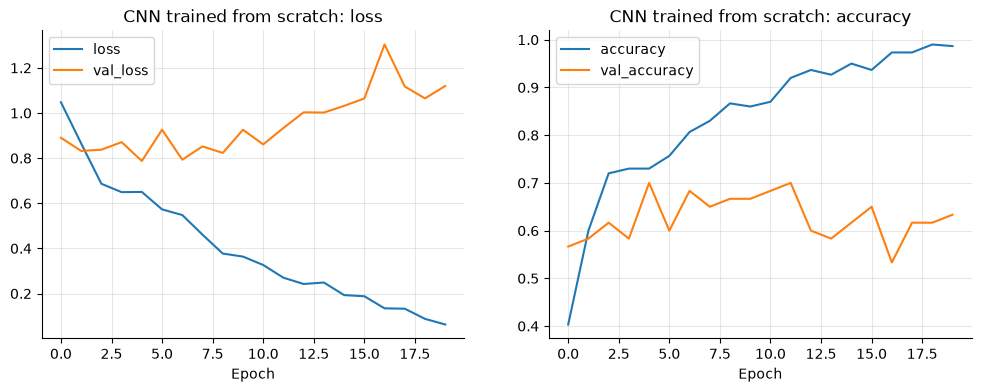

Validation accuracy: 0.633


In [14]:
keras.utils.clear_session()
keras.utils.set_random_seed(42)

cnn = keras.Sequential(
    [
        keras.Input(shape=IMAGE_SIZE + (3,)),  # input: one photo of 160 x 160 pixels
        keras.layers.Rescaling(1 / 255),  # pixels 0..255 -> 0..1
        keras.layers.Conv2D(16, 3, activation="relu"),  # 16 filters of 3 x 3 pixels: edges and colours
        keras.layers.MaxPooling2D(),  # halve the size, keep the strongest responses
        keras.layers.Conv2D(32, 3, activation="relu"),  # 32 filters: simple shapes and textures
        keras.layers.MaxPooling2D(),
        keras.layers.Conv2D(64, 3, activation="relu"),  # 64 filters: larger patterns
        keras.layers.MaxPooling2D(),
        keras.layers.Flatten(),  # all feature maps into one long vector
        keras.layers.Dropout(0.5),  # against overfitting
        keras.layers.Dense(units=len(class_names), activation="softmax"),  # one probability per flower
    ],
    name="cnn_from_scratch",
)
cnn.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.Adam(1e-3), metrics=["accuracy"])
print(f"Trainable parameters of the CNN: {cnn.count_params():,}, all starting random")

cnn_history = cnn.fit(train_ds, validation_data=val_ds, epochs=20, verbose=0)
plot_curves(pd.DataFrame(cnn_history.history), "CNN trained from scratch")

results["CNN from scratch"] = cnn.evaluate(val_ds, verbose=0)[1]
print(f"Validation accuracy: {results['CNN from scratch']:.3f}")
cnn.save("models/cnn_from_scratch.keras")  # for the final comparison on the test set in step 6

**Result.** The CNN trained from scratch reaches a validation accuracy of only **0.633, 38 of the 60 photos**, against 0.867 for the dense head on the MobileNetV2 features: transfer learning gets **14 more validation photos right**. The CNN overfits strongly: its training accuracy climbs to about 0.99, while its validation accuracy jumps around between 0.53 and 0.70, and its validation loss rises again from about epoch 10. With 300 photos, its 85,795 random weights learn to memorise the training photos instead of learning what a flower looks like. This confirms our claim: with this little data, a pretrained network is needed.

**→ Next:** the dense head also overfits a little. Can data augmentation reduce this, and does it improve the validation accuracy?

## 5. Improving the Model with Data Augmentation

**Why this step.** The head of step 4 memorised the 300 training photos: training accuracy 1.0, validation 0.867. With so few photos, the model sees every flower in only one position, size and orientation.

**Data augmentation** shows the model a slightly different version of every training photo in every epoch: randomly mirrored, rotated and zoomed. A mirrored or slightly turned rose is still a rose, so the model has to learn what a flower looks like instead of memorising exact photos. It is like having more photos without collecting any. The augmentation layers are only active during training; for evaluation, prediction and the app they pass the photos through unchanged.

**What changes compared with step 4.** Because the photos change every epoch, their features change too, so they cannot be extracted once: the frozen base now runs inside the model, on every photo in every epoch. Training is therefore much slower, and 10 epochs are used.

### Which Augmentations, and Why

An augmentation must change a photo only in ways that keep the label true. We chose the first three:

| Augmentation | Used? | Why |
|---|---|---|
| Horizontal flip | ✅ yes | A mirrored flower is still the same flower |
| Small rotation (±36°) | ✅ yes | Photos are taken at slightly different angles |
| Small zoom (±10 %) | ✅ yes | Photos are taken from different distances |
| Vertical flip | ❌ no | Most photos have a natural up and down (sky above, stems and ground below), so a vertical flip creates scenes that never occur. It would only suit close-ups taken from above, and the small rotation already covers tilted photos |
| Brightness / contrast | ⚠️ not used | Photos are taken in different light, but with 300 photos we keep it to the three standard changes |
| Colour (hue) changes | ❌ no | Colour is a key clue: sunflowers are recognised by their yellow, and a rose turned purple would be misleading |

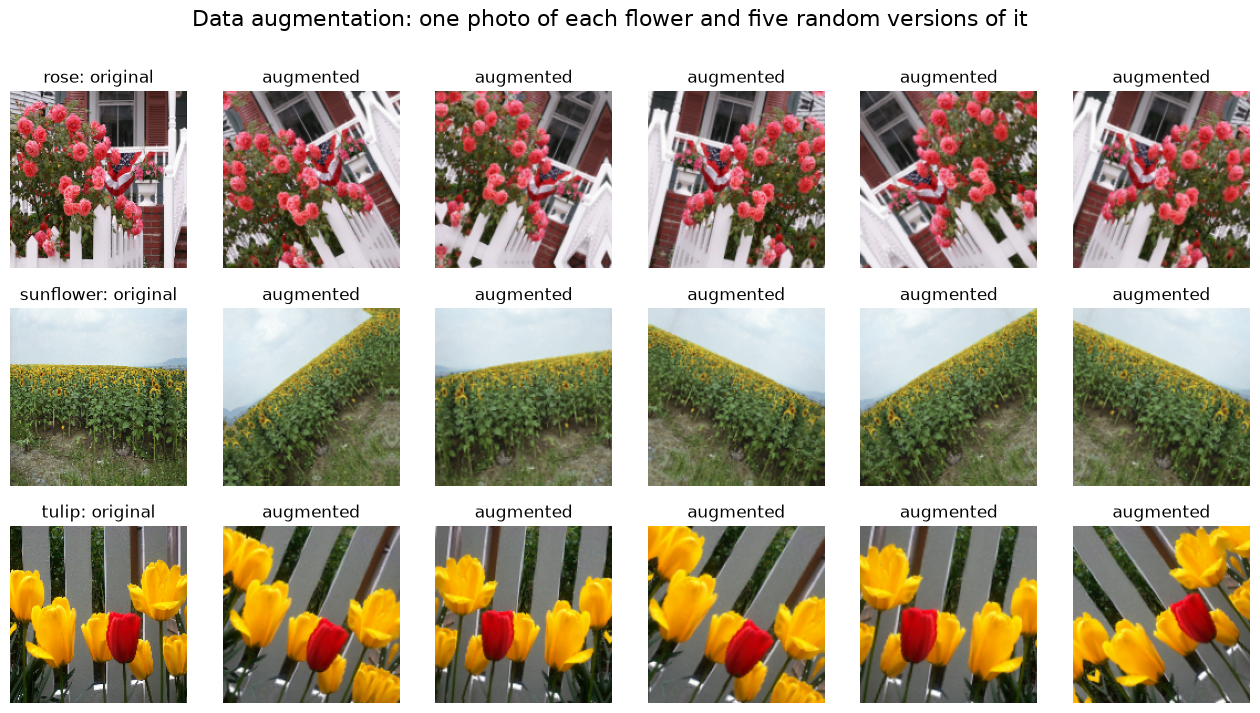

In [15]:
# The augmentation block: three random changes that keep a flower the same flower
augmentation = keras.Sequential(
    [
        keras.layers.RandomFlip("horizontal"),  # mirror left <-> right (no vertical flip: most photos have sky above and ground below)
        keras.layers.RandomRotation(0.1),  # turn by up to 10 % of a full turn (36 degrees) in either direction
        keras.layers.RandomZoom(0.1),  # zoom in or out by up to 10 %
    ],
    name="augmentation",
)

# For each flower: the first photo of that flower in the batch from step 3, then five random augmented versions
fig, axes = plt.subplots(len(class_names), 6, figsize=(16, 8))
for row, name in enumerate(class_names):
    index = int(np.where(labels.numpy() == row)[0][0])  # position of the first photo with this label in the batch
    photo = images[index:index + 1]  # keep it as a batch of one photo, as the layers expect
    axes[row, 0].imshow(photo[0].numpy().astype("uint8"))
    axes[row, 0].set_title(f"{name}: original")
    for ax in axes[row, 1:]:
        ax.imshow(augmentation(photo, training=True)[0].numpy().astype("uint8"))  # training=True switches the random changes on
        ax.set_title("augmented")
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Data augmentation: one photo of each flower and five random versions of it", fontsize=16)
plt.show()

**Result.** Every augmented version still clearly shows the same flower: the roses at the fence, the sunflower field and the tulips are mirrored, tilted and moved slightly closer or further away. The rotations fill the corners with stretched pixels from the edge of the photo, which the model learns to ignore. The label stays true for every version, which is the rule for a good augmentation.

Model: "augmented_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

D:\projects\neuefische\week5\w5d5-image-classifier-transfer-learning\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


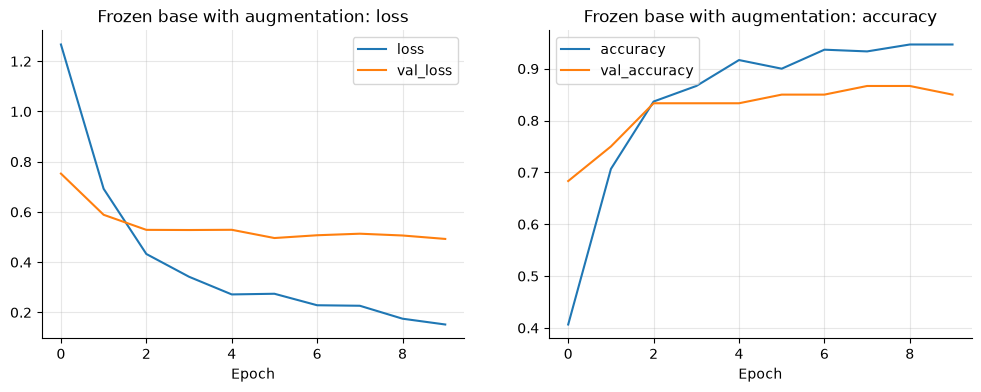

Validation accuracy: 0.850


In [16]:
keras.utils.clear_session()  # start from a clean Keras state
keras.utils.set_random_seed(42)  # the same random starting weights in every run

# One model from raw photo to probabilities: augmentation -> scaling -> frozen base -> new head
augmented_model = keras.Sequential(
    [
        keras.Input(shape=IMAGE_SIZE + (3,)),  # input: one photo of 160 x 160 pixels
        augmentation,  # random flip, rotation and zoom, only during training
        keras.layers.Rescaling(scale=1 / 127.5, offset=-1),  # pixels 0..255 -> -1..1, like mobilenet_v2.preprocess_input
        base,  # the same frozen MobileNetV2 base as in step 4
        keras.layers.Dropout(0.2),  # a new head: the same layers as in step 4, with new random weights
        keras.layers.Dense(units=len(class_names), activation="softmax"),
    ],
    name="augmented_model",  # a clear name in summary() and inside the saved model
)
augmented_model.summary()  # the layers of the model, and how many weights are trained or frozen
augmented_model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(1e-3),
    metrics=["accuracy"],
)
# Train on the photo datasets, not on the feature tables: the base runs on every photo in every epoch
history = augmented_model.fit(train_ds, validation_data=val_ds, epochs=10, verbose=0)
plot_curves(pd.DataFrame(history.history), "Frozen base with augmentation")

results["Frozen base + augmentation"] = augmented_model.evaluate(val_ds, verbose=0)[1]
print(f"Validation accuracy: {results['Frozen base + augmentation']:.3f}")

augmented_model.save("models/augmentation.keras")  # this model already takes raw photos, so the app can use it directly


**Result.** The frozen base with augmentation reaches a validation accuracy of 0.850, 51 of the 60 photos, one photo fewer than the dense head of step 4.

The learning curves show that augmentation **reduces the overfitting**: the training accuracy rises to 0.947 instead of 1.0, because the model never sees exactly the same photo twice, and the validation loss falls to about 0.5 and stays there, instead of rising again as in step 4. The model is less over-confident. But the validation accuracy does not improve: within 10 epochs it levels off at 0.85.

The model is saved as `models/augmentation.keras`. It already takes raw photos and contains its scaling, so the app can use it directly.

### Comparing the Models

**Why.** We choose our final model on the validation set only; the test set is still locked. The table puts everything we need for the choice side by side: the validation accuracy, the number of correct photos, and the gap between training and validation accuracy, which shows how much a model memorises. Chance is the baseline both models must beat.

In [17]:
# One row per model: everything needed to compare them and choose one
comparison = pd.DataFrame(
    [
        {
            "model": "Features + dense head",
            "approach": "features extracted once, head trained on the table",
            "epochs": 30,
            "training accuracy": head_history.history["accuracy"][-1],  # last epoch
            "validation accuracy": results["Features + dense head"],
        },
        {
            "model": "Frozen base + augmentation",
            "approach": "base inside the model, photos changed at random every epoch",
            "epochs": 10,
            "training accuracy": history.history["accuracy"][-1],  # on augmented photos, with dropout active
            "validation accuracy": results["Frozen base + augmentation"],
        },
        {
            "model": "CNN from scratch",
            "approach": "small CNN, all weights learnt from the 300 photos",
            "epochs": 20,
            "training accuracy": cnn_history.history["accuracy"][-1],
            "validation accuracy": results["CNN from scratch"],
        },
        {
            "model": "Chance (always the same flower)",
            "approach": "no model, baseline",
            "epochs": 0,
            "training accuracy": 1 / 3,
            "validation accuracy": 1 / 3,
        },
    ]
).set_index("model")

comparison["correct (of 60)"] = (comparison["validation accuracy"] * len(y_valid)).round().astype(int)  # accuracy -> number of photos
comparison["gap (overfitting)"] = comparison["training accuracy"] - comparison["validation accuracy"]  # large gap = memorising

comparison.sort_values("validation accuracy", ascending=False).style.format(precision=3).set_caption(
    "Comparison of the models on the validation set (60 photos)"
)

,approach,epochs,training accuracy,validation accuracy,correct (of 60),gap (overfitting)
model,,,,,,
Features + dense head,"features extracted once, head trained on the table",30,1.000,0.867,52,0.133
Frozen base + augmentation,"base inside the model, photos changed at random every epoch",10,0.947,0.850,51,0.097
CNN from scratch,"small CNN, all weights learnt from the 300 photos",20,0.987,0.633,38,0.353
Chance (always the same flower),"no model, baseline",0,0.333,0.333,20,0.000


### Our Decision

| | Features + dense head | Frozen base + augmentation |
|---|---|---|
| Validation accuracy | **0.867** (52 / 60) | 0.850 (51 / 60) |
| Gap training vs validation | 0.133 | **0.097** |
| Training time | seconds | about a minute |
| Complexity | simpler: features once, one dense layer | base runs in every epoch |

Both transfer learning models are far ahead of the CNN trained from scratch (0.633, 38 / 60) and of chance (0.333), so the choice is between the two of them.

**We choose the features + dense head.** With 60 validation photos, one photo is 0.017, so the two models are only **one photo apart**: they are practically tied. When two models are tied, the simpler one is the better choice, and the dense head is simpler and trains in seconds instead of a minute.

**What we learnt from step 5.** Augmentation did what it is meant to do: it reduced the overfitting, the gap fell from 0.133 to 0.097, and the validation loss stopped rising. But less overfitting did not mean a higher validation accuracy. The pretrained MobileNetV2 features already do most of the work, so on this data the extra technique adds little.

**→ Next:** step 6 unlocks the test set, to see how good the chosen model really is on photos that played no part in any decision.

## 6. Evaluating All Models on the Test Set

**Why this step.** In step 5 we chose our model by its validation accuracy. Choosing makes that score a little too optimistic: we picked the model that happened to do best on those 60 photos. The **test set** has played no part in any decision, so it gives one honest final score. It is used **once**, here, and we do not change our choice afterwards: if we picked whichever model scores best on the test set, it would become just another validation set.

We load all saved models from their files, as after a restart, and the test photos with the same `IMAGE_SIZE` and `shuffle=False`, so that the order of the photos and their labels stays fixed. Then we answer three questions: How good are the models really? Which flowers does the chosen model confuse? And which photos does it get wrong, and why?

In [18]:
# The test photos: the same size as before, not shuffled, so photos, labels and predictions stay in the same order
test_ds = keras.utils.image_dataset_from_directory(DATA / "test", image_size=IMAGE_SIZE, shuffle=False)

# Load all saved models from their files: they take raw photos and contain their own scaling
saved = {
    "Features + dense head": keras.models.load_model("models/dense_head.keras"),
    "Frozen base + augmentation": keras.models.load_model("models/augmentation.keras"),
    "CNN from scratch": keras.models.load_model("models/cnn_from_scratch.keras"),
}

# One row per model: validation and test accuracy, and the number of correct test photos
rows = []
for name, model in saved.items():
    rows.append(
        {
            "model": name,
            "validation accuracy": model.evaluate(val_ds, verbose=0)[1],  # evaluate returns [loss, accuracy]
            "test accuracy": model.evaluate(test_ds, verbose=0)[1],
        }
    )
rows.append({"model": "Chance (always the same flower)", "validation accuracy": 1 / 3, "test accuracy": 1 / 3})

final_table = pd.DataFrame(rows).set_index("model")
final_table["correct test photos (of 30)"] = (final_table["test accuracy"] * 30).round().astype(int)
final_table.style.format(precision=3).set_caption("Final results: validation (60 photos) and test accuracy (30 photos)")

Found 30 files belonging to 3 classes.


D:\projects\neuefische\week5\w5d5-image-classifier-transfer-learning\.venv\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'rm_sprop', because it has 4 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


,validation accuracy,test accuracy,correct test photos (of 30)
model,,,
Features + dense head,0.867,0.900,27
Frozen base + augmentation,0.850,0.867,26
CNN from scratch,0.633,0.633,19
Chance (always the same flower),0.333,0.333,10


**Result.** The chosen dense head classifies **27 of the 30 test photos** correctly, a test accuracy of 0.900. The model with augmentation gets 26 of 30 (0.867), the CNN trained from scratch only 19 of 30 (0.633), and chance 10 of 30. Transfer learning gets 8 more test photos right than the CNN from scratch.

- **Was the validation accuracy a fair estimate?** Yes. The chosen dense head scores 0.867 on the validation set and 0.900 on the test set: one photo more than expected, since one test photo is 3.3 percentage points. The validation set did not mislead our choice.
- **Was the choice right?** The model with augmentation scores one photo fewer on the test set, as it did on the validation set: the two models are practically tied on both. The test set confirms the choice of the simpler dense head, and we would not change it anyway, because the test set is only for reporting.

### Which Flowers Does the Chosen Model Confuse?

**Why.** Accuracy says *how often* the model is right, not *where* it goes wrong. The **confusion matrix** shows, for every true flower (rows), what the model predicted (columns): the diagonal holds the correct answers, every number off the diagonal is a mistake, and its position shows which flower was taken for which. In step 3 we expected roses and tulips to be confused most; here we check that.

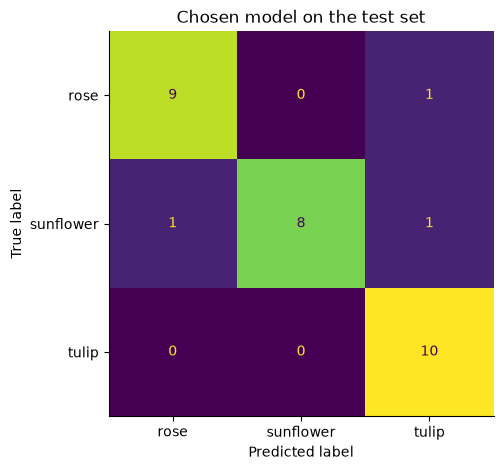

In [19]:
best = saved["Features + dense head"]  # the model we chose by its validation accuracy in step 5

y_test = np.concatenate([labels for _, labels in test_ds])  # the true labels, in the fixed order of the test set
test_images = np.concatenate([images for images, _ in test_ds])  # the photos, in the same order
probabilities = best.predict(test_ds, verbose=0)  # one row of 3 probabilities per photo
y_pred = probabilities.argmax(axis=1)  # the predicted flower: the one with the highest probability

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=class_names, colorbar=False, ax=ax)
ax.set_title("Chosen model on the test set")
ax.grid(False)  # no grid lines across the matrix
plt.show()

**Result.** All 10 tulips are correct. 9 of 10 roses are correct; one is taken for a tulip. 8 of 10 sunflowers are correct; one is taken for a rose and one for a tulip.

Our expectation from step 3 was only half right: the rose and tulip confusion does occur, once, but **two of the three mistakes are sunflowers**, the class that looked easiest because of its yellow petals and dark centre.

### Which Photos Does It Get Wrong?

**Why.** The confusion matrix counts the mistakes; the photos show *why* they happen. For every misclassified test photo we show its true label, the predicted label and how sure the model was. In step 3 we suspected that the model might rely on the background, for example "sky means sunflower"; the wrong photos show whether that happens.

3 of 30 test photos are wrong


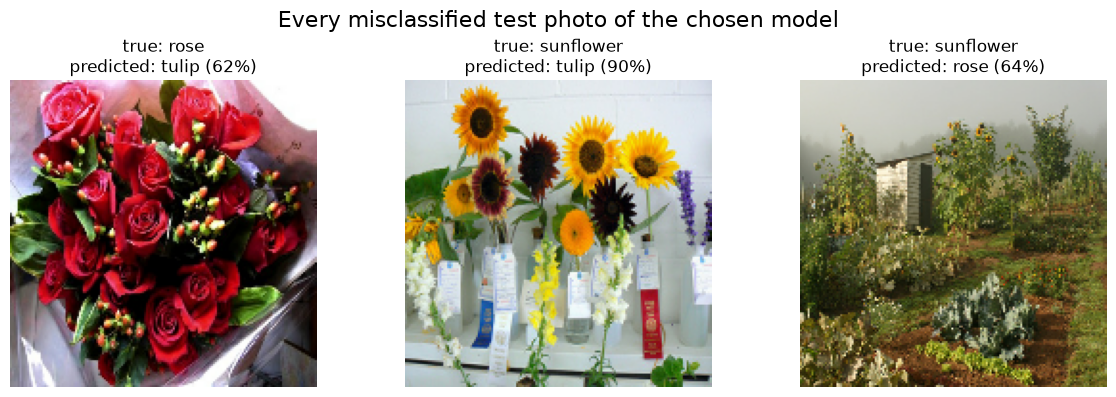

In [20]:
wrong = np.where(y_pred != y_test)[0]  # the positions of the misclassified photos
print(f"{len(wrong)} of {len(y_test)} test photos are wrong")

if len(wrong) > 0:
    fig, axes = plt.subplots(1, len(wrong), figsize=(4 * len(wrong), 4), squeeze=False)  # one box per wrong photo
    for ax, i in zip(axes.flat, wrong):
        ax.imshow(test_images[i].astype("uint8"))
        ax.set_title(
            f"true: {class_names[y_test[i]]}\n"
            f"predicted: {class_names[y_pred[i]]} ({probabilities[i].max():.0%})"  # the probability of its answer
        )
        ax.axis("off")
    fig.suptitle("Every misclassified test photo of the chosen model", fontsize=16)
    plt.tight_layout()  # keep the title clear of the photo labels
    plt.show()

**Result.** None of the three wrong photos is a close-up of a single flower, the way most training photos are:

- **A rose bouquet** wrapped in paper, full of small green buds: predicted as tulip (62 %).
- **A sunflower display** in a shop, with dark red sunflowers, other flowers and prize ribbons: predicted as tulip (90 %).
- **A vegetable garden** with a shed, where the sunflowers are small in the background: predicted as rose (64 %).

The model works when **the flower is the main subject** of the photo, and fails when the **scene dominates**: many flowers of different colours, or a flower that is small in the frame. This confirms our concern from step 3 that the background and the whole scene influence the model, not only the flower.

### How Sure Is the Model When It Is Wrong?

**Why.** For regression we would plot the residuals to see how far off the predictions are. For classification there are no residuals: "tulip minus rose" means nothing. The closest equivalent is the model's **confidence**, the probability it gives to its answer. If the wrong answers come with a lower probability than the correct ones, the garden centre can use it: a member of staff checks every answer below a threshold. The plot shows the confidence of every test photo, correct and wrong, and the table shows what a rule of 70 % would catch.

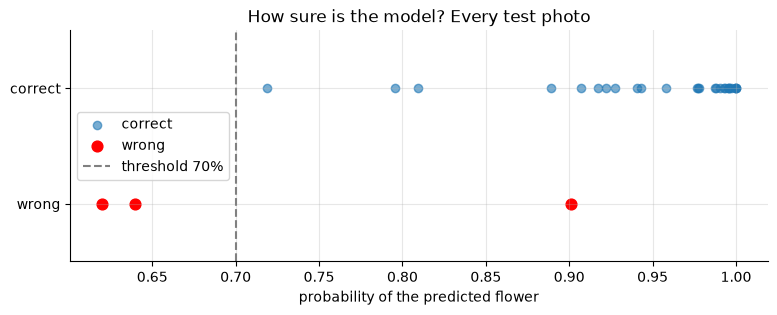

,checked by staff (below threshold),answered automatically
wrong predictions,2,1
correct predictions,0,27


In [21]:
confidence = probabilities.max(axis=1)  # the probability the model gives to its own answer
correct = y_pred == y_test  # True for every correct prediction
THRESHOLD = 0.7  # a member of staff checks every answer below this probability

fig, ax = plt.subplots(figsize=(9, 3))
ax.scatter(confidence[correct], np.ones(correct.sum()), label="correct", alpha=0.6)
ax.scatter(confidence[~correct], np.zeros((~correct).sum()), color="red", label="wrong", s=60)
ax.axvline(THRESHOLD, color="grey", linestyle="--", label=f"threshold {THRESHOLD:.0%}")
ax.set_yticks([0, 1], ["wrong", "correct"])
ax.set_ylim(-0.5, 1.5)
ax.set_xlabel("probability of the predicted flower")
ax.set_title("How sure is the model? Every test photo")
ax.legend(loc="center left")
plt.show()

# What the rule "check every answer below the threshold" would do on the test set
pd.DataFrame(
    {
        "checked by staff (below threshold)": [(~correct & (confidence < THRESHOLD)).sum(), (correct & (confidence < THRESHOLD)).sum()],
        "answered automatically": [(~correct & (confidence >= THRESHOLD)).sum(), (correct & (confidence >= THRESHOLD)).sum()],
    },
    index=["wrong predictions", "correct predictions"],
).style.set_caption(f"What the rule \"check every answer below {THRESHOLD:.0%}\" does on the 30 test photos")

**Result.** All 27 correct answers come with a probability of at least 0.72. Two of the three wrong answers are below 70 % (0.62 and 0.64), so the rule **"a member of staff checks every answer below 70 %"** would catch them, while sending none of the correct answers to staff: only 2 of the 30 photos would need a person. The third mistake, the sunflower display, is made with 90 %, so the rule catches most mistakes, but not all.

The threshold of 70 % was chosen while looking at these 30 test photos, so before using it the garden centre should confirm it on more photos.

### What This Means for the Garden Centre

- The model chooses the right care guide for **9 of 10 photos**, against 1 of 3 by guessing.
- It is reliable when the photo shows **one kind of flower as the main subject**. The website should ask customers for a close-up of a single flower.
- Answers below **70 %** should be checked by a member of staff; on the test set this catches two of the three mistakes and costs a check for only 2 of 30 photos.
- The model can only answer rose, sunflower or tulip: a daisy would still get one of the three labels, so the website has to say which flowers the service covers.

**→ Next:** try the model in the app, the way a customer would use it.

## 7. Trying the Model in the App

**Why this step.** The test set shows how the model does on 30 photos from the same collection as the training photos. A customer's photo is different: another camera, another garden, another light. In the app we use the model the way a customer would, with photos of our own.

The repository contains a small [Streamlit](https://docs.streamlit.io/) app, `app.py`. It loads a model from `models/`, prepares an uploaded photo the same way as `image_dataset_from_directory` (resized to 160 x 160), and shows the probability of each flower. It works with our saved models because they take raw photos and contain their own scaling. We start it in a terminal in the repository folder:

```bash
uv run streamlit run app.py
```

We chose `dense_head.keras`, our final model, and uploaded three kinds of photos: clear close-ups of each flower, a harder photo (a bouquet or a field), and a flower the model does not know.

### How the Garden Centre Would Use It

```text
customer uploads a photo  ->  model
                                |-- at least 70 % sure:  care guide sent automatically
                                '-- below 70 % sure:     a member of staff checks the photo, then sends the guide
```

Customers never see the model: they get their care guide, or a message that a member of staff will check their photo. Staff only see the uncertain photos, about 2 of 30 on the test set. The app shows both cases: above 70 % it names the flower, below 70 % it shows the two best guesses and says that a member of staff will check the photo. It also tells customers which flowers are covered and asks for a close-up of one flower.

| Photo | What it shows | Prediction | Probability | Correct? |
|---|---|---|---|---|
| 1 | *(fill in)* | | | |
| 2 | | | | |
| 3 | | | | |
| 4 | | | | |
| 5 | a flower that is not a rose, sunflower or tulip | | | — |

**Result.** *(fill in after trying the app: Are the close-ups right, and with a high probability? Is the hard photo less certain, as the wrong test photos in step 6 suggest? What does the model answer for the unknown flower, and with which probability?)*